# Task-2 (Week-7)

**Date** :- (24-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Generate detailed, structured reports that summarize admission model findings, highlighting key features, insights from data analysis, and recommendations for admission committees.

In [1]:
# import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv('Admission_Prediction.csv')
print("Dataset loaded:", df.shape)

Dataset loaded: (1000, 18)


In [2]:
# summarize admission status and applicant metrics
status_counts = df['Admission Status'].value_counts()
accept_rate = (df['Admission Status'] == 'Accepted').mean() * 100

summary_by_status = df.groupby('Admission Status')[
    ['GRE Score', 'TOEFL Score', 'CGPA', 'SOP', 'LOR', 'Research', 'Chance of Admit']
].mean().round(2)

print("Admission Status Counts:")
print(status_counts)
print(f"\nOverall Acceptance Rate: {accept_rate:.2f}%")
print("\nAverage Profile by Admission Status:")
print(summary_by_status)

Admission Status Counts:
Admission Status
Rejected    565
Accepted    435
Name: count, dtype: int64

Overall Acceptance Rate: 43.50%

Average Profile by Admission Status:
                  GRE Score  TOEFL Score  CGPA   SOP   LOR  Research  \
Admission Status                                                       
Accepted             319.55       108.65  8.78  3.66  3.61      0.64   
Rejected             313.20       104.96  8.44  3.19  3.25      0.40   

                  Chance of Admit  
Admission Status                   
Accepted                     0.85  
Rejected                     0.62  


In [3]:
# analyze regional and yearly admission trends
region_summary = df.groupby('region').agg(
    Applicants=('Serial No.', 'count'),
    Accept_Rate=('Admission Status', lambda s: round((s == 'Accepted').mean() * 100, 2)),
    Avg_Chance=('Chance of Admit', lambda s: round(s.mean(), 3)),
    Avg_CGPA=('CGPA', lambda s: round(s.mean(), 2))
).sort_values(by='Accept_Rate', ascending=False)

year_summary = df.groupby('Year').agg(
    Applicants=('Serial No.', 'count'),
    Accept_Rate=('Admission Status', lambda s: round((s == 'Accepted').mean() * 100, 2)),
    Avg_Chance=('Chance of Admit', lambda s: round(s.mean(), 3))
)

print("Regional Summary:")
print(region_summary)
print("\nYearly Summary:")
print(year_summary)

Regional Summary:
           Applicants  Accept_Rate  Avg_Chance  Avg_CGPA
region                                                  
Northeast          25        56.00       0.732      8.67
West              150        52.67       0.747      8.60
Central            26        42.31       0.707      8.62
North             305        41.97       0.714      8.62
South             379        41.95       0.714      8.56
East              115        38.26       0.702      8.56

Yearly Summary:
      Applicants  Accept_Rate  Avg_Chance
Year                                     
2022         200         46.0       0.722
2023         200         44.0       0.727
2024         200         40.5       0.707
2025         200         45.0       0.721
2026         200         42.0       0.712


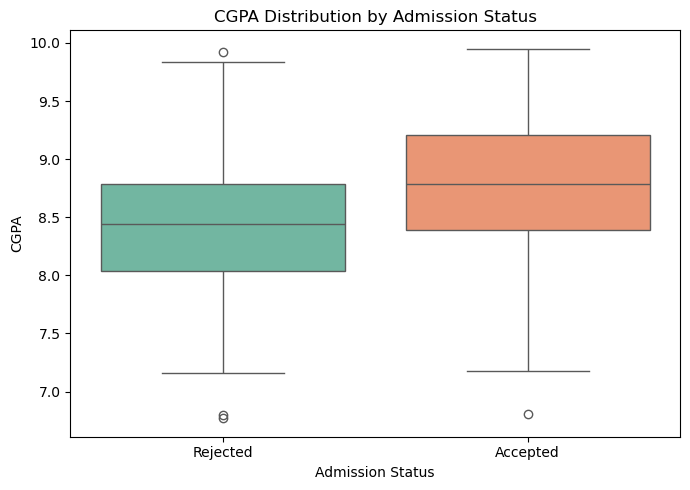

In [4]:
# plot cgpa distribution by admission status
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Admission Status', y='CGPA', hue='Admission Status', palette='Set2', legend=False)
plt.title('CGPA Distribution by Admission Status')
plt.xlabel('Admission Status')
plt.ylabel('CGPA')
plt.tight_layout()
plt.show()

In [5]:
# train model and extract key feature importances
drop_cols = [
    'Serial No.', 'Application_Date', 'Survival_Data_Note',
    'Duration_Months', 'Dropout_Event', 'Dropout-free survival',
    'Admission Status', 'Chance of Admit'
]
X = df.drop(columns=drop_cols)
y = df['Chance of Admit']

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=150, max_depth=10, random_state=42))
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

feature_names = pipe.named_steps['preprocessor'].get_feature_names_out()
importances = pipe.named_steps['model'].feature_importances_

feat_df = pd.DataFrame({
    'Feature': [name.replace('num__', '').replace('cat__', '') for name in feature_names],
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

print(f"Model R2: {r2_score(y_test, y_pred):.4f}, MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print("\nTop 10 Features:")
print(feat_df.to_string(index=False))

Model R2: 0.2484, MAE: 0.0867

Top 10 Features:
                                                 Feature  Importance
                                                    CGPA    0.287549
                                                    Year    0.132725
                                               GRE Score    0.111807
                                             TOEFL Score    0.101297
                                                     LOR    0.061140
                                                     SOP    0.059981
                                       University Rating    0.030134
                                                Research    0.018987
University_Name_Indian Institute of Technology Kharagpur    0.018564
                                            region_North    0.009368


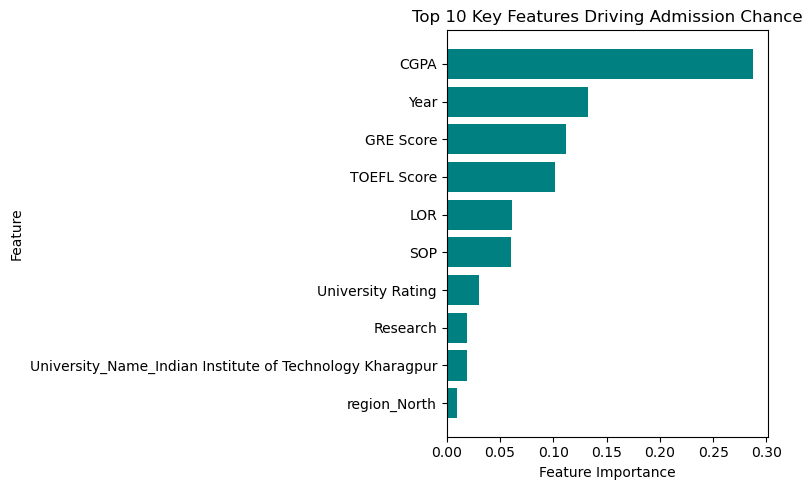

In [6]:
# plot top important features for admission
top_plot = feat_df.sort_values(by='Importance', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(top_plot['Feature'], top_plot['Importance'], color='teal')
plt.title('Top 10 Key Features Driving Admission Chance')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [7]:
# generate structured summary report and committee recommendations
corr_scores = df[num_cols + ['Chance of Admit']].corr()['Chance of Admit'].drop('Chance of Admit').sort_values(ascending=False)
research_accept = df.groupby('Research')['Admission Status'].apply(lambda s: (s == 'Accepted').mean() * 100)

report_text = f'''
============================================================
ADMISSION MODEL FINDINGS & COMMITTEE REPORT
============================================================

1. EXECUTIVE SUMMARY
- Total Applications Analyzed : {len(df)} (Years {df['Year'].min()}-{df['Year'].max()})
- Accepted Applicants         : {status_counts.get('Accepted', 0)} ({accept_rate:.2f}%)
- Rejected Applicants         : {status_counts.get('Rejected', 0)} ({100 - accept_rate:.2f}%)
- Model Performance           : R2 = {r2_score(y_test, y_pred):.4f}, MAE = {mean_absolute_error(y_test, y_pred):.4f}

2. KEY FEATURE FINDINGS
- Top Model Driver            : {feat_df.iloc[0]['Feature']} (Importance: {feat_df.iloc[0]['Importance']:.3f})
- Second Top Driver           : {feat_df.iloc[1]['Feature']} (Importance: {feat_df.iloc[1]['Importance']:.3f})
- Strongest Linear Correlates : CGPA ({corr_scores['CGPA']:.3f}), GRE Score ({corr_scores['GRE Score']:.3f}), TOEFL Score ({corr_scores['TOEFL Score']:.3f})

3. DATA ANALYSIS INSIGHTS
- Academic Gap                : Accepted mean CGPA is {summary_by_status.loc['Accepted', 'CGPA']} vs Rejected {summary_by_status.loc['Rejected', 'CGPA']}.
- Test Score Gap              : Accepted mean GRE is {summary_by_status.loc['Accepted', 'GRE Score']} vs Rejected {summary_by_status.loc['Rejected', 'GRE Score']}.
- Research Advantage          : Acceptance rate with Research = {research_accept.get(1, 0):.1f}% vs without = {research_accept.get(0, 0):.1f}%.
- Regional Variation          : Highest acceptance rate in {region_summary.index[0]} ({region_summary.iloc[0]['Accept_Rate']}%), lowest in {region_summary.index[-1]} ({region_summary.iloc[-1]['Accept_Rate']}%).

4. RECOMMENDATIONS FOR ADMISSION COMMITTEES
- Prioritize CGPA and standardized test scores (GRE/TOEFL) as primary screening indicators.
- Give structured weight to prior Research experience, as it shows a clear boost in admission probability.
- Review SOP and LOR scores consistently alongside quantitative thresholds near the 0.75 chance boundary.
- Monitor regional acceptance differences to ensure fair outreach across underrepresented regions.
'''

print(report_text)
with open('admission_findings_report.txt', 'w', encoding='utf-8') as f:
    f.write(report_text.strip() + '\n')


ADMISSION MODEL FINDINGS & COMMITTEE REPORT

1. EXECUTIVE SUMMARY
- Total Applications Analyzed : 1000 (Years 2022-2026)
- Accepted Applicants         : 435 (43.50%)
- Rejected Applicants         : 565 (56.50%)
- Model Performance           : R2 = 0.2484, MAE = 0.0867

2. KEY FEATURE FINDINGS
- Top Model Driver            : CGPA (Importance: 0.288)
- Second Top Driver           : Year (Importance: 0.133)
- Strongest Linear Correlates : CGPA (0.348), GRE Score (0.283), TOEFL Score (0.264)

3. DATA ANALYSIS INSIGHTS
- Academic Gap                : Accepted mean CGPA is 8.78 vs Rejected 8.44.
- Test Score Gap              : Accepted mean GRE is 319.55 vs Rejected 313.2.
- Research Advantage          : Acceptance rate with Research = 55.5% vs without = 31.4%.
- Regional Variation          : Highest acceptance rate in Northeast (56.0%), lowest in East (38.26%).

4. RECOMMENDATIONS FOR ADMISSION COMMITTEES
- Prioritize CGPA and standardized test scores (GRE/TOEFL) as primary screening indic